In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from functools import partial

from cdrmip_extremes import (
    file_search, load_raw, amoc, processing, utils, io_disk
)
from cdrmip_extremes.utils import _map_leaves, reduce_member_tree
from cdrmip_extremes.configs import DATA_DIR, RAW_DIR, PROC_DIR, FIG_DIR, CDR_MODELS as models, CDR_EXPTS as expts, COLOUR_DICT

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
crossing_years = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'crossing_years', 'CDRMIP', as_dataarray=True,model_order=models)
)

In [4]:
save_dir = RAW_DIR / 'siconc'
data = defaultdict(lambda: defaultdict(dict))

for model in models:
    for expt in ['1pctCO2','1pctCO2-cdr']:
        path = str(save_dir / expt / f'{model}_{expt}_siconc.nc')
        print(path)
        ds = xr.open_mfdataset(
            path,
            use_cftime=True,
            chunks={'time': 120},
        )
        data[model][expt] = ds
data = utils.defaultdict_to_dict(data)

/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2/ACCESS-ESM1-5_1pctCO2_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2-cdr/ACCESS-ESM1-5_1pctCO2-cdr_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2/CanESM5_1pctCO2_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2-cdr/CanESM5_1pctCO2-cdr_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2/CESM2_1pctCO2_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2-cdr/CESM2_1pctCO2-cdr_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2/CNRM-ESM2-1_1pctCO2_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2-cdr/CNRM-ESM2-1_1pctCO2-cdr_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2/GFDL-ESM4_1pctCO2_siconc.nc
/g/data/if69/sc1326/repos/cdrmip_extremes/data/raw/siconc/1pctCO2-cdr/GFDL-ESM4_1pctCO2-cdr_siconc.nc
/g/data/if69/sc1326/

In [5]:
data

{'ACCESS-ESM1-5': {'1pctCO2': <xarray.Dataset> Size: 779MB
  Dimensions:    (time: 1800, j: 300, i: 360)
  Coordinates:
    * time       (time) object 14kB 0101-01-16 12:00:00 ... 0250-12-16 12:00:00
    * j          (j) int32 1kB 0 1 2 3 4 5 6 7 ... 292 293 294 295 296 297 298 299
    * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
      latitude   (j, i) float64 864kB dask.array<chunksize=(300, 360), meta=np.ndarray>
      longitude  (j, i) float64 864kB dask.array<chunksize=(300, 360), meta=np.ndarray>
      type       |S7 7B ...
  Data variables:
      siconc     (time, j, i) float32 778MB dask.array<chunksize=(120, 300, 360), meta=np.ndarray>,
  '1pctCO2-cdr': <xarray.Dataset> Size: 2GB
  Dimensions:    (time: 4080, j: 300, i: 360)
  Coordinates:
    * time       (time) object 33kB 0241-01-16 12:00:00 ... 0580-12-16 12:00:00
    * j          (j) int32 1kB 0 1 2 3 4 5 6 7 ... 292 293 294 295 296 297 298 299
    * i          (i) int32 1kB 0 1 2 3 4 5 6

In [6]:
branch_date_overrides = {} 

expt = '1pctCO2-cdr'
concat = defaultdict(lambda: defaultdict(dict))
for model, expts in data.items():
    parent = expts.get('1pctCO2', {})
    ds = expts['1pctCO2-cdr']
    concat[model] = processing.concatenate_branches(
        ds, parent, branch_date=branch_date_overrides.get(model), realign_years = (0,140)
    ).assign_attrs(experiment_id=expt)

concat = utils.defaultdict_to_dict(concat)

Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-15 12:00:00, child relabeled to start 0140-01-15 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 013

In [7]:
def load_areacello(models=models):
    save_dir = RAW_DIR / 'Ofx'
    data = {}
    for model in models:
        path = save_dir / f"{model}_areacello.nc"
        data[model] = xr.open_dataarray(path)
    return data

In [8]:
areacello = load_areacello()

### Ensure coordinates are consistent ###

In [9]:
for model, ds in concat.items():
    print(model)
    print(ds.dims)
    print(list(ds.coords))

ACCESS-ESM1-5
FrozenMappingWarningOnValuesAccess({'time': 5760, 'j': 300, 'i': 360})
['j', 'i', 'latitude', 'longitude', 'type', 'time']
CanESM5
FrozenMappingWarningOnValuesAccess({'time': 4080, 'j': 291, 'i': 360})
['j', 'i', 'latitude', 'longitude', 'type', 'time']
CESM2
FrozenMappingWarningOnValuesAccess({'time': 4080, 'nj': 384, 'ni': 320})
['lat', 'lon', 'ni', 'nj', 'time']
CNRM-ESM2-1
FrozenMappingWarningOnValuesAccess({'time': 4080, 'y': 294, 'x': 362})
['lat', 'lon', 'type', 'time']
GFDL-ESM4
FrozenMappingWarningOnValuesAccess({'time': 4080, 'y': 576, 'x': 720})
['lat', 'lon', 'x', 'y', 'time']
MIROC-ES2L
FrozenMappingWarningOnValuesAccess({'time': 5760, 'y': 256, 'x': 360})
['y', 'x', 'latitude', 'longitude', 'type', 'time']
NorESM2-LM
FrozenMappingWarningOnValuesAccess({'time': 4788, 'j': 384, 'i': 360})
['j', 'i', 'latitude', 'longitude', 'type', 'time']
UKESM1-0-LL
FrozenMappingWarningOnValuesAccess({'time': 5760, 'j': 330, 'i': 360})
['j', 'i', 'latitude', 'longitude', 'ty

In [10]:
for model, ds in concat.items():
    # Check and rename 'lat' to 'latitude'
    if 'lat' in ds.coords:
        ds = ds.rename({'lat': 'latitude'})
    
    # Check and rename 'lon' to 'longitude'
    if 'lon' in ds.coords:
        ds = ds.rename({'lon': 'longitude'})
    
    concat[model] = ds

In [11]:
for model, si in concat.items():
    if 'ni' in list(si.dims):
        print(f"Changing {model} dim 'ni'")
        concat[model] = si.rename({'ni':'i','nj':'j'})
    elif 'y' in list(si.dims):
        print(f"Changing {model} dim 'y'")
        concat[model] = si.rename({'x':'i','y':'j'})

Changing CESM2 dim 'ni'
Changing CNRM-ESM2-1 dim 'y'
Changing GFDL-ESM4 dim 'y'
Changing MIROC-ES2L dim 'y'


In [12]:
for model, si in areacello.items():
    if 'ni' in list(si.dims):
        print(f"Changing {model} dim 'ni'")
        areacello[model] = si.rename({'ni':'i','nj':'j'})
    if 'y' in list(si.dims):
        print(f"Changing {model} dim 'y'")
        areacello[model] = si.rename({'x':'i','y':'j'})
    if 'nlat' in list(si.dims):
        print(f"Changing {model} dim 'nlat'")
        areacello[model] = si.rename({'nlat':'j','nlon':'i'})

Changing CESM2 dim 'nlat'
Changing CNRM-ESM2-1 dim 'y'
Changing GFDL-ESM4 dim 'y'
Changing MIROC-ES2L dim 'y'


## Calculate Regional Averages ##

In [13]:
si_weighted = {model:{} for model in models}
for model, siconc in concat.items():
    print(f"processing {model}")
    arctic = siconc.where(siconc['latitude']>=60)
    antarctic = siconc.where(siconc['latitude']<=-60)
    for pole, pole_si in [('Arctic',arctic),('Antarctic',antarctic)]:
        weighted = pole_si.weighted(
            weights=areacello[model].fillna(0)
        ).mean(dim=('i','j'))
        si_weighted[model][pole] = weighted.compute()

processing ACCESS-ESM1-5
processing CanESM5
processing CESM2
processing CNRM-ESM2-1
processing GFDL-ESM4
processing MIROC-ES2L
processing NorESM2-LM
processing UKESM1-0-LL


In [14]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.cm as cm
from matplotlib.colors import ListedColormap, BoundaryNorm

In [15]:
colour_dict = COLOUR_DICT

In [16]:
def plot_siconc(siconc,fig,ax,region,crossing_years,expt):

    for model in models:
        da = siconc[model][region].groupby('time.year').mean(dim='time').siconc
        da_rolling = da.rolling(year=21,center=True,min_periods=1).mean()
        da.plot(ax=ax,color=colour_dict[model],linewidth=2,alpha=0.3)
        da_rolling.plot(ax=ax,label=model,color=colour_dict[model],linewidth=2)

        # plot 1.5 crossing year
        gwl_up = int(crossing_years[model][expt].sel(branch='ramp_up',gwl=1.5).values)
        gwl_down = int(crossing_years[model][expt].sel(branch='ramp_down',gwl=1.5).values)

        ax.scatter(
            gwl_up,
            da_rolling.sel(year=gwl_up),
           marker='^',
          color=colour_dict[model],
          s=400,
          # label='1.5$^o$C ramp-up'
        )
        ax.scatter(gwl_down,
           da_rolling.sel(year=gwl_down),
           marker='v',
          color=colour_dict[model],
          s=400,
          # label='1.5$^o$C ramp-down'
                  )

    ax.set_ylabel('Sea Ice Concentration (%)',fontsize=12)

    ax.set_xlabel('Year',fontsize=12)
    ax.set_xlim([0,350])
    ax.axvline(x = 140, color = 'gray',linewidth=1.0,linestyle='--',alpha=0.7)
    ax.axvline(x = 280, color = 'gray',linewidth=1.0,linestyle='--',alpha=0.7)
     

    ax.set_title(f"{region} Sea Ice Concentration",fontsize=18)


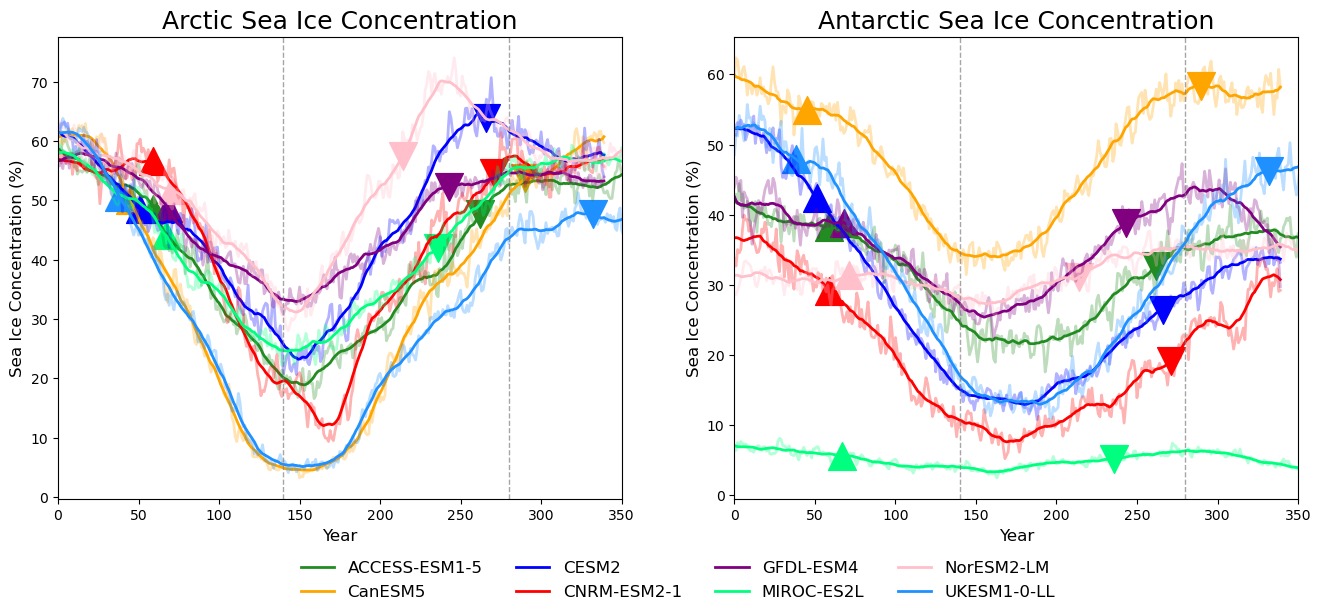

In [17]:
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(16,6))

plot_siconc(si_weighted,fig,ax1,'Arctic',crossing_years,'1pctCO2-cdr')
plot_siconc(si_weighted,fig,ax2,'Antarctic',crossing_years,'1pctCO2-cdr')
ax1.legend(loc='lower center',bbox_to_anchor = (1.1,-0.25),ncol=4,frameon=False,fontsize=12)

In [ ]:
fig.savefig(
    FIG_DIR / "supplementary" / "figure_S30.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)